# Stage 1, HW 5 — APEM simulator
The simulator is in `apem.py`. Each run is a dict like a human run, so `fraught_mask` and the forward-hold % fraught from HW 3 work on it.

In [1]:
# Stage 1, HW 5
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import slider_logs as sl
from apem import apem, GRAPHS

/home/aalok/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# fraught_mask (same as HW 3)
def fraught_mask(run):
    A = run["A"]                         # 7x7, no self-loops
    s = sl.sign_correct(run)             # s = weights * X, shape T x 7
    no_zeros = np.all(s != 0, axis=1)
    mixed = ~(np.all(s > 0, axis=1) | np.all(s < 0, axis=1))
    delta = np.sign(s) * (s @ A)         # row k of s @ A is A @ s_k (A is symmetric)
    no_switch = np.all(delta >= 0, axis=1)
    return no_zeros & mixed & no_switch

# forward hold (HW 3 method 1): each row lasts until the next row, time limit 300 s (lab) or 180 s (cloud)
def fraught_percent_hold(run, T_limit=300):
    t = run["t"]
    T_end = t[-1] if run["success"] else max(T_limit, t[-1])
    dt = np.diff(np.append(t, T_end))
    return 100 * np.sum(dt * fraught_mask(run)) / T_end

## Sanity checks (seed 0)
On the Full graph no state is fraught, so every run should have zero fraught rows.

In [3]:
# Full graph, 200 runs: no fraught rows at all
rng = np.random.default_rng(0)
full_runs = [apem(GRAPHS["Full"], rng=rng) for _ in range(200)]
n_fraught = [fraught_mask(run).sum() for run in full_runs]
print("runs with any fraught row:", sum(k > 0 for k in n_fraught))
assert sum(n_fraught) == 0

runs with any fraught row: 0


In [4]:
# mean gap between events should be about mu/n = 0.1/7 s; positions stay in [-1, 1]
gaps = np.concatenate([np.diff(run["t"][:-1]) for run in full_runs])   # last gap of a failed run is cut at T, so leave it out
print("mean gap = %.5f s   (0.1/7 = %.5f s)" % (gaps.mean(), 0.1 / 7))
print("min, max position:", min(run["X"].min() for run in full_runs), max(run["X"].max() for run in full_runs))
assert all(np.all(np.abs(run["X"]) <= 1) for run in full_runs)

mean gap = 0.01427 s   (0.1/7 = 0.01429 s)
min, max position: -1.0 1.0


success: True   end time = 46.6 s   fraught = 54.9 %


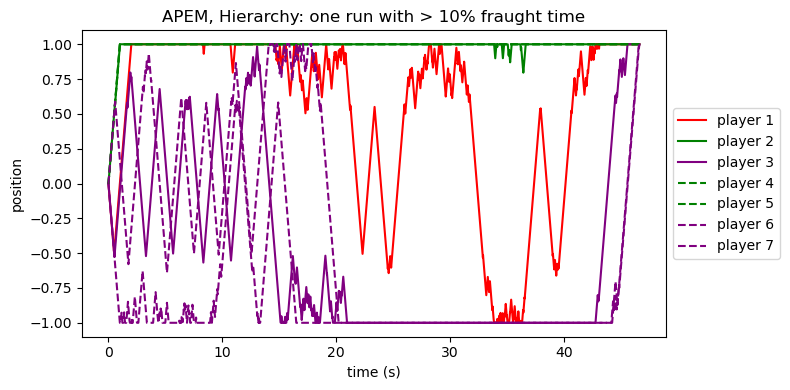

In [5]:
# one Hierarchy run with > 10% fraught time: the first one found with seed 0
rng = np.random.default_rng(0)
run = apem(GRAPHS["Hierarchy"], rng=rng)
while fraught_percent_hold(run) <= 10:
    run = apem(GRAPHS["Hierarchy"], rng=rng)
print("success:", run["success"], "  end time = %.1f s" % run["t"][-1], "  fraught = %.1f %%" % fraught_percent_hold(run))

# apex red, branch {2, 4, 5} green, branch {3, 6, 7} purple (dashed = leaves)
colors = {1: "red", 2: "green", 4: "green", 5: "green", 3: "purple", 6: "purple", 7: "purple"}
plt.figure(figsize=(8, 4))
for k in range(1, 8):
    plt.plot(run["t"], run["X"][:, k - 1], color=colors[k], linestyle="-" if k <= 3 else "--", label="player %d" % k)
plt.xlabel("time (s)")
plt.ylabel("position")
plt.title("APEM, Hierarchy: one run with > 10% fraught time")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

## 5.3 Hierarchy, 1000 runs (T = 300, seed 0), next to the humans
Humans: CL Hierarchy from `runs_fraught.csv` (HW 3). All 63 rounds are kept, since these are the numbers that reproduce the paper.

In [6]:
# 1000 APEM runs on the Hierarchy
rng = np.random.default_rng(0)
sim = [apem(GRAPHS["Hierarchy"], T=300, rng=rng) for _ in range(1000)]
sim_success = np.array([run["success"] for run in sim])
sim_time = np.array([run["t"][-1] for run in sim])                  # time to consensus if successful
sim_fraught = np.array([fraught_percent_hold(run) for run in sim])

# humans: CL Hierarchy
hum = pd.read_csv("runs_fraught.csv")
hum = hum[(hum["dataset"] == "CL") & (hum["topology"] == "Hierarchy")]

def summary(success, time, fraught):
    return {"runs": len(success),
            "success rate %": 100 * np.mean(success),
            "mean time to consensus (s)": np.mean(time[success]),
            "s.d. time to consensus (s)": np.std(time[success], ddof=1),
            "mean % fraught (hold)": np.mean(fraught),
            "# runs > 10% fraught": np.sum(fraught > 10)}

pd.DataFrame({
    "humans (CL Hierarchy)": summary(hum["success"].values, hum["duration"].values, hum["fraught % (hold)"].values),
    "APEM (Hierarchy)": summary(sim_success, sim_time, sim_fraught),
}).round(2)

,humans (CL Hierarchy),APEM (Hierarchy)
runs,63.00,1000.00
success rate %,92.06,96.90
mean time to consensus (s),61.61,43.61
s.d. time to consensus (s),52.97,61.76
mean % fraught (hold),11.58,26.29
# runs > 10% fraught,18.00,404.00


## 5.3b Reconcile with the authors' code (`Code/runapem.m`)
`apem_osf.py` is a line-by-line port of `runapem.m` and the functions it calls (`updatestatecapem`, `getagreelaopt`, `crop`, `fraught`, `winningorthant`, `PWLF`).

Differences from `apem.py`:

| # | `runapem.m` | `apem.py` | matters? |
|---|---|---|---|
| 1 | draws 7 latencies Exp(mean μ), the smallest one checks in | one Exp(mean μ/7), random agent | no, same distribution |
| 2 | check-in → maybe switch → move for the latency | move → check-in → maybe switch | no, same sequence after the first step |
| 3 | first move is a fixed step of μ = 0.1 | first interval is random | tiny |
| 4 | `thist(2)` is never set: the state after the first move is stamped t = 0 | first row at t = 0 is s = 0 | tiny |
| 5 | loops while t < 300, last step can overshoot | stops exactly at T | only failed runs |
| 6 | agreement \|A s\| / row sums with 1s on the diagonal | \|s_i + Σ neighbours\| / (deg + 1) | no, same formula |
| 7 | `fraught.m`: not fraught if any player has esum > fsum | `fraught_mask`: sign(s_i)(A s)_i ≥ 0 | no, same test (checked below) |
| 8 | % fraught by time warp: PWLF on 1001 evenly spaced times | forward hold | small for the model (it moves in straight lines) |
| 9 | % fraught only for **successful** runs | all runs | yes, failed runs are long and fraught |
| 10 | keeps only runs with % fraught > 10% (up to 1000) for the averaging figure; it never reports a mean % fraught | all runs | yes, the script does not estimate % fraught |
| 11 | Matlab random numbers | NumPy | runs cannot be matched one to one |

In [7]:
# 5.3b port of the authors' code
import apem_osf

# authors' measure: time warp (1001 points), share of fraught states; fraught_mask = fraught.m (checked next)
def fraught_percent_osf(run):
    S = apem_osf.warp(run)
    return 100 * np.mean(fraught_mask({"A": run["A"], "weights": np.ones(7), "X": S}))

# check: the port of fraught.m and fraught_mask agree on every warped state of 20 runs
rng = np.random.default_rng(0)
for _ in range(20):
    run = apem_osf.runapem(GRAPHS["Hierarchy"], rng=rng)
    S = apem_osf.warp(run)
    slow = [apem_osf.fraught(s, run["A"]) for s in S]
    fast = fraught_mask({"A": run["A"], "weights": np.ones(7), "X": S})
    assert np.array_equal(slow, fast)
print("fraught.m and fraught_mask agree")

fraught.m and fraught_mask agree


1000 Hierarchy runs of the port at (a_θ, s_θ) = (0.5, 0.5), seed 0, next to the humans and `apem.py` (the 1000 runs from 5.3). Two measures: forward hold over all runs (as in 5.3) and the authors' measure (time warp, successful runs only).

In [8]:
# 1000 runs of the port on the Hierarchy
rng = np.random.default_rng(0)
port = [apem_osf.runapem(GRAPHS["Hierarchy"], timelimit=300, rng=rng) for _ in range(1000)]
port_success = np.array([run["success"] for run in port])
port_time = np.array([run["t"][-1] for run in port])
port_hold = np.array([fraught_percent_hold(run) for run in port])
port_osf = np.array([fraught_percent_osf(run) for run in port])
sim_osf = np.array([fraught_percent_osf(run) for run in sim])

# 5.3 summary plus the authors' measure (successful runs only)
def summary_b(success, time, hold, osf):
    out = summary(success, time, hold)
    out["mean % fraught, successful runs (warp)"] = np.mean(osf[success])
    out["# successful runs > 10% (warp)"] = np.sum(osf[success] > 10)
    return out

pd.DataFrame({
    "humans (CL Hierarchy)": summary_b(hum["success"].values, hum["duration"].values, hum["fraught % (hold)"].values, hum["fraught % (interp)"].values),
    "apem.py": summary_b(sim_success, sim_time, sim_fraught, sim_osf),
    "port of runapem.m": summary_b(port_success, port_time, port_hold, port_osf),
}).round(2)

,humans (CL Hierarchy),apem.py,port of runapem.m
runs,63.00,1000.00,1000.00
success rate %,92.06,96.90,97.50
mean time to consensus (s),61.61,43.61,43.22
s.d. time to consensus (s),52.97,61.76,59.17
mean % fraught (hold),11.58,26.29,26.06
# runs > 10% fraught,18.00,404.00,384.00
"mean % fraught, successful runs (warp)",10.47,24.18,24.34
# successful runs > 10% (warp),16.00,371.00,357.00


Coarse a_θ × s_θ sweep (0.3–0.7), 200 runs per cell, seed 0 in every cell, authors' code and measure. A mini version of Fig. 7c. The humans are at 10.5% by this measure (58 successful CL Hierarchy runs).

In [9]:
# sweep: % fraught (successful runs, time warp), success rate and time to consensus in each cell
values = [0.3, 0.4, 0.5, 0.6, 0.7]
rows = []
for a_th in values:
    for s_th in values:
        rng = np.random.default_rng(0)
        cell = [apem_osf.runapem(GRAPHS["Hierarchy"], atheta=a_th, stheta=s_th, rng=rng) for _ in range(200)]
        ok = [run for run in cell if run["success"]]
        rows.append({"a_th": a_th, "s_th": s_th, "success %": 100 * len(ok) / len(cell),
                     "mean time (s)": np.mean([run["t"][-1] for run in ok]),
                     "mean % fraught": np.mean([fraught_percent_osf(run) for run in ok])})
sweep = pd.DataFrame(rows)
sweep.to_csv("apem_sweep.csv", index=False)

# rows a_th, columns s_th
for col in ["mean % fraught", "success %", "mean time (s)"]:
    print(col)
    display(sweep.pivot(index="a_th", columns="s_th", values=col).round(1))

mean % fraught


s_th,0.3,0.4,0.5,0.6,0.7
a_th,,,,,
0.3,0.6,0.5,0.3,0.9,1.1
0.4,1.1,1.3,1.7,1.7,1.3
0.5,28.1,21.8,21.3,20.6,15.5
0.6,19.7,15.3,15.1,12.3,7.1
0.7,8.7,8.0,6.6,7.3,3.8


success %


s_th,0.3,0.4,0.5,0.6,0.7
a_th,,,,,
0.3,57.5,66.0,63.5,65.0,65.0
0.4,63.5,66.0,71.5,62.0,72.0
0.5,89.0,94.0,97.5,99.5,99.5
0.6,100.0,100.0,100.0,100.0,99.5
0.7,97.0,99.5,100.0,100.0,95.0


mean time (s)


s_th,0.3,0.4,0.5,0.6,0.7
a_th,,,,,
0.3,9.0,9.0,8.2,7.4,7.3
0.4,12.6,10.7,9.8,9.3,10.1
0.5,59.4,43.6,39.8,36.2,30.1
0.6,45.4,36.7,36.4,35.8,56.6
0.7,78.9,53.3,59.8,66.0,90.8


In [10]:
# cells where the model is 10-20% fraught (humans: 10.5% by this measure, 92% success, 61.6 s)
sweep[(sweep["mean % fraught"] >= 10) & (sweep["mean % fraught"] <= 20)].round(1)

,a_th,s_th,success %,mean time (s),mean % fraught
14,0.5,0.7,99.5,30.1,15.5
15,0.6,0.3,100.0,45.4,19.7
16,0.6,0.4,100.0,36.7,15.3
17,0.6,0.5,100.0,36.4,15.1
18,0.6,0.6,100.0,35.8,12.3


## 5.4 (H4) APEM unchanged on every topology, compared with humans
`apem.py`, μ = 0.1, speed = 1, 1000 runs per cell, seed 0 in every cell, at (a_θ, s_θ) = (0.5, 0.5) (paper) and (0.6, 0.5) (off the knife edge).
Lab block T = 300 s: Hierarchy, Ring, CT-Hierarchy, Full. Cloud block T = 180 s: Hierarchy, Star, Full.
Metrics: success %, mean time to consensus (successful runs), mean % fraught (forward hold, all runs),
% fraught by the authors' measure (successful runs only, 1001-point interpolation), % of runs > 10% fraught (hold).

In [11]:
# authors' measure for apem.py runs: interpolate through all rows at 1001 evenly spaced times (HW 3 method 2)
def fraught_percent_interp(run, n=1000):
    t = run["t"]
    grid = np.linspace(t[0], t[-1], n + 1)
    S = np.column_stack([np.interp(grid, t, run["X"][:, j]) for j in range(7)])
    return 100 * np.mean(fraught_mask({"A": run["A"], "weights": np.ones(7), "X": S}))

# the five metrics of one cell (used for APEM and for humans)
def metrics(success, t_end, hold, interp):
    success, t_end, hold, interp = [np.array(x) for x in [success, t_end, hold, interp]]
    success = success.astype(bool)
    return {"runs": len(success),
            "success %": 100 * success.mean(),
            "mean time (s)": t_end[success].mean(),
            "% fraught (hold)": hold.mean(),
            "% fraught (authors)": interp[success].mean(),
            "% runs > 10% (hold)": 100 * (hold > 10).mean()}

In [12]:
# APEM: 2 settings x 2 blocks, 1000 runs per cell (runs are not kept, only their metrics)
settings = {"APEM (0.5, 0.5)": (0.5, 0.5), "APEM (0.6, 0.5)": (0.6, 0.5)}
blocks = {"lab": (300, ["Hierarchy", "Ring", "CT-Hierarchy", "Full"]),
          "cloud": (180, ["Hierarchy", "Star", "Full"])}

rows = []
for source, (a_th, s_th) in settings.items():
    for block, (T, topologies) in blocks.items():
        for topology in topologies:
            rng = np.random.default_rng(0)                       # fixed seed per cell
            success, t_end, hold, interp = [], [], [], []
            for _ in range(1000):
                run = apem(GRAPHS[topology], a_th=a_th, s_th=s_th, mu=0.1, speed=1.0, T=T, rng=rng)
                success.append(run["success"])
                t_end.append(run["t"][-1])
                hold.append(fraught_percent_hold(run, T))
                interp.append(fraught_percent_interp(run))
            rows.append({"source": source, "group": block, "topology": topology, **metrics(success, t_end, hold, interp)})

apem_res = pd.DataFrame(rows)
apem_res.to_csv("apem_topologies.csv", index=False)
apem_res.round(2)

,source,group,topology,runs,success %,mean time (s),% fraught (hold),% fraught (authors),% runs > 10% (hold)
0,"APEM (0.5, 0.5)",lab,Hierarchy,1000,96.9,43.61,26.29,24.17,40.4
1,"APEM (0.5, 0.5)",lab,Ring,1000,100.0,18.28,14.29,14.19,43.6
2,"APEM (0.5, 0.5)",lab,CT-Hierarchy,1000,95.7,46.55,26.45,23.55,40.6
3,"APEM (0.5, 0.5)",lab,Full,1000,21.7,41.19,0.00,0.00,0.0
4,"APEM (0.5, 0.5)",cloud,Hierarchy,1000,92.7,33.43,26.30,21.19,40.6
5,"APEM (0.5, 0.5)",cloud,Star,1000,100.0,12.88,0.00,0.00,0.0
6,"APEM (0.5, 0.5)",cloud,Full,1000,23.1,43.08,0.00,0.00,0.0
7,"APEM (0.6, 0.5)",lab,Hierarchy,1000,100.0,32.27,14.87,14.84,41.1
8,"APEM (0.6, 0.5)",lab,Ring,1000,100.0,32.70,8.48,8.40,34.3
9,"APEM (0.6, 0.5)",lab,CT-Hierarchy,1000,100.0,46.22,13.49,13.46,43.4


In [13]:
# humans: drop incomplete runs, the 1-row aborted rounds (T == 1) and CC rounds with a bot
h = pd.read_csv("runs_fraught.csv").merge(pd.read_csv("runs_table.csv")[["file", "wave", "T", "end"]], on=["file", "wave"])
h = h[(h["end"] != "incomplete") & (h["T"] != 1) & ~((h["dataset"] == "CC") & h["bot"])]

cells = {"CL": ["Hierarchy", "Ring", "Full"], "EL": ["Hierarchy", "CT-Hierarchy", "Ring"], "CC": ["Hierarchy", "Star", "Full"]}
rows = []
for dataset, topologies in cells.items():
    for topology in topologies:
        d = h[(h["dataset"] == dataset) & (h["topology"] == topology)]
        rows.append({"source": "humans", "group": dataset, "topology": topology,
                     **metrics(d["success"], d["duration"], d["fraught % (hold)"], d["fraught % (interp)"])})
humans = pd.DataFrame(rows)
humans.round(2)

,source,group,topology,runs,success %,mean time (s),% fraught (hold),% fraught (authors),% runs > 10% (hold)
0,humans,CL,Hierarchy,61,95.08,61.61,11.96,10.47,29.51
1,humans,CL,Ring,58,91.38,87.29,16.03,15.71,50.00
2,humans,CL,Full,63,82.54,87.01,0.00,0.00,0.00
3,humans,EL,Hierarchy,51,94.12,59.61,12.12,8.20,27.45
4,humans,EL,CT-Hierarchy,51,82.35,57.13,17.62,7.74,35.29
5,humans,EL,Ring,51,88.24,66.89,21.56,17.81,52.94
6,humans,CC,Hierarchy,40,92.50,45.75,12.45,10.87,32.50
7,humans,CC,Star,39,100.00,39.94,0.00,0.00,0.00
8,humans,CC,Full,36,97.22,53.91,0.00,0.00,0.00


Each ratio is taken within its own block (APEM) or dataset (humans): CL and EL are compared with the lab block, CC with the cloud block.

In [14]:
# comparison table: (what, human dataset, APEM block, metric, top, bottom)
res = pd.concat([apem_res, humans]).set_index(["source", "group", "topology"])
comparisons = [
    ("% fraught, Ring / Hierarchy",  "CL", "lab",   "% fraught (hold)", "Ring",         "Hierarchy"),
    ("% fraught, Ring / Hierarchy",  "EL", "lab",   "% fraught (hold)", "Ring",         "Hierarchy"),
    ("% fraught, CT / Hierarchy",    "EL", "lab",   "% fraught (hold)", "CT-Hierarchy", "Hierarchy"),
    ("time, Star / Hierarchy",       "CC", "cloud", "mean time (s)",    "Star",         "Hierarchy"),
    ("success, Star / Hierarchy",    "CC", "cloud", "success %",        "Star",         "Hierarchy"),
    ("time, Full / Hierarchy",       "CL", "lab",   "mean time (s)",    "Full",         "Hierarchy"),
    ("success, Full / Hierarchy",    "CL", "lab",   "success %",        "Full",         "Hierarchy"),
    ("time, Full / Hierarchy",       "CC", "cloud", "mean time (s)",    "Full",         "Hierarchy"),
    ("success, Full / Hierarchy",    "CC", "cloud", "success %",        "Full",         "Hierarchy"),
]

rows = []
for what, dataset, block, col, top, bottom in comparisons:
    row = {"comparison": what, "humans from": dataset, "APEM block": block,
           "humans": res.loc[("humans", dataset, top), col] / res.loc[("humans", dataset, bottom), col]}
    for source in settings:
        row[source] = res.loc[(source, block, top), col] / res.loc[(source, block, bottom), col]
    rows.append(row)
compare = pd.DataFrame(rows)

# one summary line per comparison: direction of each ratio (up = above 1), and whether APEM matches humans
def direction(x):
    if np.isnan(x):
        return "n/a"                                     # no successful run in a cell
    return "up" if x > 1 else ("down" if x < 1 else "equal")

for _, r in compare.iterrows():
    line = f"{r['humans from']} {r['comparison']}: humans {r['humans']:.2f} ({direction(r['humans'])})"
    for s in settings:
        match = "same" if direction(r[s]) == direction(r["humans"]) else "DIFFERENT"
        line += f" | {s} {r[s]:.2f} ({direction(r[s])}, {match})"
    print(line)
compare.round(2)

CL % fraught, Ring / Hierarchy: humans 1.34 (up) | APEM (0.5, 0.5) 0.54 (down, DIFFERENT) | APEM (0.6, 0.5) 0.57 (down, DIFFERENT)
EL % fraught, Ring / Hierarchy: humans 1.78 (up) | APEM (0.5, 0.5) 0.54 (down, DIFFERENT) | APEM (0.6, 0.5) 0.57 (down, DIFFERENT)
EL % fraught, CT / Hierarchy: humans 1.45 (up) | APEM (0.5, 0.5) 1.01 (up, same) | APEM (0.6, 0.5) 0.91 (down, DIFFERENT)
CC time, Star / Hierarchy: humans 0.87 (down) | APEM (0.5, 0.5) 0.39 (down, same) | APEM (0.6, 0.5) 0.55 (down, same)
CC success, Star / Hierarchy: humans 1.08 (up) | APEM (0.5, 0.5) 1.08 (up, same) | APEM (0.6, 0.5) 1.01 (up, same)
CL time, Full / Hierarchy: humans 1.41 (up) | APEM (0.5, 0.5) 0.94 (down, DIFFERENT) | APEM (0.6, 0.5) 3.49 (up, same)
CL success, Full / Hierarchy: humans 0.87 (down) | APEM (0.5, 0.5) 0.22 (down, same) | APEM (0.6, 0.5) 0.18 (down, same)
CC time, Full / Hierarchy: humans 1.18 (up) | APEM (0.5, 0.5) 1.29 (up, same) | APEM (0.6, 0.5) 2.38 (up, same)
CC success, Full / Hierarchy: h

,comparison,humans from,APEM block,humans,"APEM (0.5, 0.5)","APEM (0.6, 0.5)"
0,"% fraught, Ring / Hierarchy",CL,lab,1.34,0.54,0.57
1,"% fraught, Ring / Hierarchy",EL,lab,1.78,0.54,0.57
2,"% fraught, CT / Hierarchy",EL,lab,1.45,1.01,0.91
3,"time, Star / Hierarchy",CC,cloud,0.87,0.39,0.55
4,"success, Star / Hierarchy",CC,cloud,1.08,1.08,1.01
5,"time, Full / Hierarchy",CL,lab,1.41,0.94,3.49
6,"success, Full / Hierarchy",CL,lab,0.87,0.22,0.18
7,"time, Full / Hierarchy",CC,cloud,1.18,1.29,2.38
8,"success, Full / Hierarchy",CC,cloud,1.05,0.25,0.13


In [15]:
# ranking of topologies by % fraught (hold), within each human dataset and the matching APEM block
for dataset, topologies in cells.items():
    block = "cloud" if dataset == "CC" else "lab"
    def ranking(source, group):
        values = {top: round(res.loc[(source, group, top), "% fraught (hold)"], 2) for top in topologies}
        order = sorted(topologies, key=lambda top: (-values[top], top))     # highest first, ties alphabetical
        text = order[0]
        for a, b in zip(order, order[1:]):
            text += (" = " if values[a] == values[b] else " > ") + b      # "=" for a tie (e.g. both 0%)
        return text
    hum_rank = ranking("humans", dataset)
    print(f"{dataset}: humans {hum_rank}")
    for source in settings:
        apem_rank = ranking(source, block)
        print(f"    {source}: {apem_rank}  ({'same' if apem_rank == hum_rank else 'DIFFERENT'})")

CL: humans Ring > Hierarchy > Full
    APEM (0.5, 0.5): Hierarchy > Ring > Full  (DIFFERENT)
    APEM (0.6, 0.5): Hierarchy > Ring > Full  (DIFFERENT)
EL: humans Ring > CT-Hierarchy > Hierarchy
    APEM (0.5, 0.5): CT-Hierarchy > Hierarchy > Ring  (DIFFERENT)
    APEM (0.6, 0.5): Hierarchy > CT-Hierarchy > Ring  (DIFFERENT)
CC: humans Hierarchy > Full = Star
    APEM (0.5, 0.5): Hierarchy > Full = Star  (same)
    APEM (0.6, 0.5): Hierarchy > Full = Star  (same)
